In [3]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

columns = ["ra", "dec", "z", "weight"]

galaxy = pd.read_csv(
    "processed/boss_cmass_north_galaxy.csv.gz",
    usecols=columns,
)
random = pd.read_csv(
    "processed/boss_cmass_north_random.csv.gz",
    usecols=columns,
)

joint = pd.read_csv("../comparison/results/joint_summary.csv")
OMEGA_M = joint.loc[0, "Omega_m"]

pd.DataFrame({
    "galaxies": [len(galaxy)],
    "randoms": [len(random)],
    "Omega_m": [OMEGA_M],
})

,galaxies,randoms,Omega_m
0,568776,2959170,0.304


In [4]:
z_grid = np.linspace(0, 0.70, 10001)
dz = z_grid[1] - z_grid[0]

inv_e = 1 / (
    OMEGA_M * (1 + z_grid)**3 + 1 - OMEGA_M
)**0.5

integral = np.zeros(len(z_grid))
integral[1:] = np.cumsum((inv_e[:-1] + inv_e[1:]) * dz / 2)


def coordinates(df):
    distance = 2997.92458 * np.interp(df["z"].values, z_grid, integral)
    ra = df["ra"].values * np.pi / 180
    dec = df["dec"].values * np.pi / 180

    return np.column_stack((
        distance * np.cos(dec) * np.cos(ra),
        distance * np.cos(dec) * np.sin(ra),
        distance * np.sin(dec),
    ))


xyz_g = coordinates(galaxy)
xyz_r = coordinates(random)

wg = galaxy["weight"].values
wr = random["weight"].values

tree_g = cKDTree(xyz_g)
tree_r = cKDTree(xyz_r)

edges = np.arange(20.0, 165.0, 5.0)

In [5]:
z_grid = np.linspace(0, 0.70, 10001)
dz = z_grid[1] - z_grid[0]

inv_e = 1 / (
    OMEGA_M * (1 + z_grid)**3 + 1 - OMEGA_M
)**0.5

integral = np.zeros(len(z_grid))
integral[1:] = np.cumsum((inv_e[:-1] + inv_e[1:]) * dz / 2)


def coordinates(df):
    distance = 2997.92458 * np.interp(df["z"].values, z_grid, integral)
    ra = df["ra"].values * np.pi / 180
    dec = df["dec"].values * np.pi / 180

    return np.column_stack((
        distance * np.cos(dec) * np.cos(ra),
        distance * np.cos(dec) * np.sin(ra),
        distance * np.sin(dec),
    ))


xyz_g = coordinates(galaxy)
xyz_r = coordinates(random)

wg = galaxy["weight"].values
wr = random["weight"].values

tree_g = cKDTree(xyz_g)
tree_r = cKDTree(xyz_r)

edges = np.arange(20.0, 165.0, 5.0)

In [7]:
wg = np.array(galaxy["weight"], dtype=np.float64, order="C", copy=True)
wr = np.array(random["weight"], dtype=np.float64, order="C", copy=True)
edges = np.array(edges, dtype=np.float64, order="C", copy=True)

In [8]:
timings = []

for name, first_tree, second_tree, first_weight, second_weight in [
    ("DD", tree_g, tree_g, wg, wg),
    ("DR", tree_g, tree_r, wg, wr),
    ("RR", tree_r, tree_r, wr, wr),
]:
    start = time.perf_counter()

    counts = first_tree.count_neighbors(
        second_tree,
        edges,
        weights=(first_weight, second_weight),
        cumulative=False,
    )[1:]

    pd.DataFrame({
        "s_low": edges[:-1],
        "s_high": edges[1:],
        "weighted_pairs": counts,
    }).to_csv("results/boss_" + name + ".csv", index=False)

    timings.append({
        "pairs": name,
        "seconds": time.perf_counter() - start,
    })

    pd.DataFrame(timings).to_csv(
        "results/boss_pair_timing.csv",
        index=False,
    )

pd.DataFrame(timings)

,pairs,seconds
0,DD,25.788765
1,DR,111.771697
2,RR,534.922633


In [9]:
dd = pd.read_csv("results/boss_DD.csv")["weighted_pairs"].values
dr = pd.read_csv("results/boss_DR.csv")["weighted_pairs"].values
rr = pd.read_csv("results/boss_RR.csv")["weighted_pairs"].values

dd = dd / (np.sum(wg)**2 - np.sum(wg**2))
dr = dr / (np.sum(wg) * np.sum(wr))
rr = rr / (np.sum(wr)**2 - np.sum(wr**2))

assert (rr > 0).all()

s = (edges[:-1] + edges[1:]) / 2
xi = (dd - 2 * dr + rr) / rr

correlation = pd.DataFrame({
    "s_low": edges[:-1],
    "s_high": edges[1:],
    "s": s,
    "DD_normalized": dd,
    "DR_normalized": dr,
    "RR_normalized": rr,
    "xi": xi,
    "s2_xi": s**2 * xi,
})

correlation.to_csv("results/boss_correlation.csv", index=False)

pd.DataFrame({
    "Omega_m": [OMEGA_M],
    "galaxies": [len(galaxy)],
    "randoms": [len(random)],
    "sum_weight_galaxy": [np.sum(wg)],
    "sum_weight_random": [np.sum(wr)],
}).to_csv("results/boss_correlation_settings.csv", index=False)

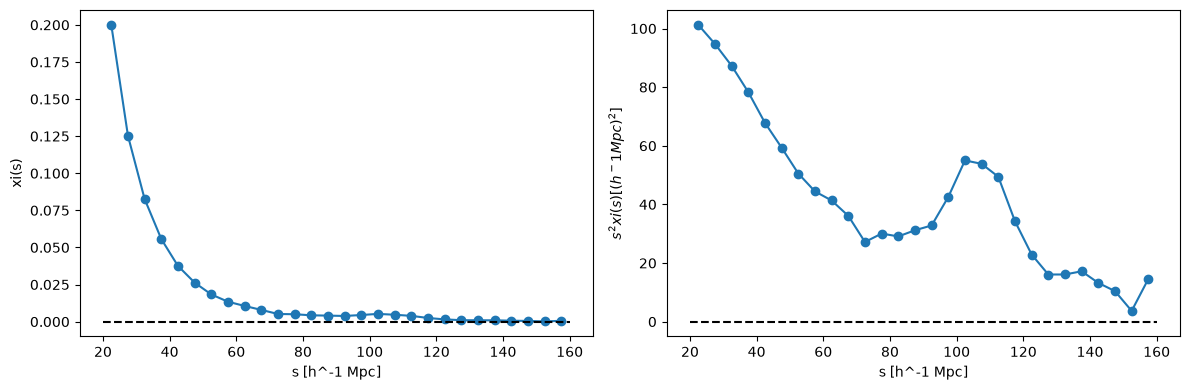

In [12]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(s, xi, "o-")
plt.plot([edges[0], edges[-1]], [0, 0], "k--")
plt.xlabel("s [h^-1 Mpc]")
plt.ylabel("xi(s)")

plt.subplot(1, 2, 2)
plt.plot(s, s**2 * xi, "o-")
plt.plot([edges[0], edges[-1]], [0, 0], "k--")
plt.xlabel("s [h^-1 Mpc]")
plt.ylabel("$s^2 xi(s) [(h^-1 Mpc)^2]$")

plt.tight_layout()
plt.savefig("results/boss_correlation.png", dpi=200)
plt.show()